# Cohort Analysis Project

In [1]:
#Import Libraries
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import seaborn as sns
import datetime as dt
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.simplefilter("ignore")
pd.set_option('display.max_columns', 100)
from pydantic_settings import BaseSettings
from ydata_profiling import ProfileReport 
%matplotlib inline

In [2]:
df_retail = pd.read_csv("./data/online_retail_II.csv")

# Inspection of Dataset

In [3]:
df_retail.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [4]:
df_retail.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [ ]:
profile = ProfileReport(df_retail, title="Profiling Report")
profile

<Figure size 640x480 with 0 Axes>

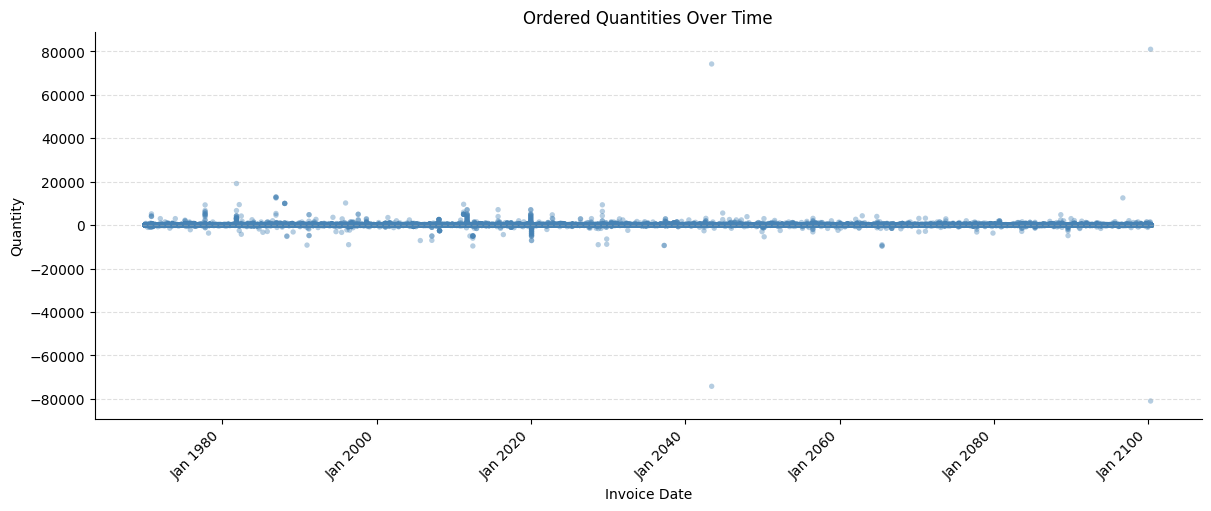

In [5]:
fig = plt.figure()            # an empty figure with no axes
fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")      # a figure with a single Axes

ax.scatter(
    df_retail["InvoiceDate"],
    df_retail["Quantity"],
    alpha=0.4,
    s=15,
    color="steelblue",
    edgecolors="none"
)

# Titles and labels
ax.set(
    title="Ordered Quantities Over Time",
    xlabel="Invoice Date",
    ylabel="Quantity"
)

# Formatting
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)

plt.xticks(rotation=45, ha="right")
plt.show()

In [7]:
df_retail['Quantity'].sort_values(ascending=False).head(10)

1065882    80995
587080     74215
90857      19152
127168     12960
127166     12960
127169     12744
1027583    12540
127167     12480
192197     10200
135028     10000
Name: Quantity, dtype: int64

In [8]:
df_retail['Quantity'].sort_values(ascending=True).head(10)

1065883   -80995
587085    -74215
303996     -9600
750990     -9600
750991     -9600
529729     -9360
507225     -9360
156488     -9200
750989     -9058
428975     -9000
Name: Quantity, dtype: int64

In [9]:
df_retail.loc[[1065882, 1065883, 587080, 587085]]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346.0,United Kingdom


In [12]:
df_retail[df_retail['Invoice']=='581483']

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom


In [13]:
df_retail[df_retail['Invoice']=='541431']

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom


In [14]:
df_retail.nsmallest(10, 'Quantity')[
    ['Invoice', 'StockCode', 'Description',
     'Quantity', 'InvoiceDate', 'Customer ID']
]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Customer ID
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,16446.0
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,12346.0
303996,519017,22759,NaN,-9600,2010-08-13 09:14:00,NaN
750990,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,NaN
750991,556691,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,NaN
507225,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,15838.0
529729,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,2010-12-02 14:23:00,15838.0
156488,504311,22197,NaN,-9200,2010-04-12 14:39:00,NaN
750989,556687,23003,Printing smudges/thrown away,-9058,2011-06-14 10:36:00,NaN
194372,507913,10120,Zebra invcing error,-9000,2010-05-11 17:16:00,NaN


### Although these two orders were fully returned, the original purchase records will remain in the dataset for the subsequent analysis. Only the corresponding return transactions will be excluded. This ensures that the customers' initial purchasing activity is preserved when determining their cohort membership and analysing retention.

## Data Cleaning and Preparating Steps
- Dropping rows with missing Customer IDs, since they are the base for our Cohort Analysis
- Filtering out records from December 2009, to analyse the full years of 2010 - 2011
- Analysing and Dropping row entries of returns - represented by negative order quantities in the dataset while looking into the highest and lowest order quantities
- Analysing and Dropping duplicate rows

- Excluding records of test purchases since they would distort the Cohort Analysis by distorting: Number of purchases, first purchase dates, monthly revenue, customer retention

- Adding a new column representing the line total of each record 

In [15]:
df_retail = df_retail[(df_retail['InvoiceDate']>='2010-01-01')&(df_retail['InvoiceDate']<'2012-01-01')]

In [16]:
df_retail_duplicates = df_retail[df_retail.duplicated(keep=False)]
df_retail_duplicates

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
45388,493435,21678,PAISLEY PATTERN STICKERS,2,2010-01-04 12:57:00,0.85,13206.0,United Kingdom
45401,493435,21678,PAISLEY PATTERN STICKERS,2,2010-01-04 12:57:00,0.85,13206.0,United Kingdom
45487,493442,20751,FUNKY WASHING UP GLOVES ASSORTED,1,2010-01-04 13:36:00,2.10,13821.0,United Kingdom
45488,493442,20751,FUNKY WASHING UP GLOVES ASSORTED,1,2010-01-04 13:36:00,2.10,13821.0,United Kingdom
45497,493442,20712,JUMBO BAG WOODLAND ANIMALS,1,2010-01-04 13:36:00,1.95,13821.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067136,581538,22068,BLACK PIRATE TREASURE CHEST,1,2011-12-09 11:34:00,0.39,14446.0,United Kingdom
1067150,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,2011-12-09 11:34:00,2.49,14446.0,United Kingdom
1067153,581538,22992,REVOLVER WOODEN RULER,1,2011-12-09 11:34:00,1.95,14446.0,United Kingdom
1067160,581538,22694,WICKER STAR,1,2011-12-09 11:34:00,2.10,14446.0,United Kingdom


In [17]:
df_retail_duplicates['Country'].unique()
# quick assessment of a given country-level structure in the duplicates

array(['United Kingdom', 'Spain', 'Belgium', 'Sweden', 'France', 'EIRE',
       'Italy', 'Germany', 'Netherlands', 'Cyprus', 'Portugal',
       'Australia', 'Norway', 'Switzerland', 'Poland', 'Lithuania',
       'Japan', 'Iceland', 'Channel Islands', 'Denmark', 'Hong Kong',
       'Unspecified', 'Israel'], dtype=object)

In [18]:
df_retail.dropna(subset=["Customer ID"], inplace=True)
df_retail.drop_duplicates(inplace=True)

## Setting appropriate column data types:
- Invoice, Customer ID: INT
- InvoiceDate: Datetime

In [19]:
df_retail["InvoiceDate"] = pd.to_datetime(df_retail["InvoiceDate"])

In [20]:
df_retail = df_retail.astype({'Invoice': 'object', 'Customer ID': 'int'})
# List of dictionnaries  {'Invoice':'int'}

In [21]:
product_descriptions = df_retail['Description'].unique().tolist()
product_descriptions

['This is a test product.',
 'RETRO SPOTS BUTTER DISH',
 'RETRO SPOT MUG',
 'RETRO SPOT LARGE MILK JUG',
 'NEW ENGLAND CERAMIC CAKE SERVER',
 'HAND OPEN SHAPE GOLD',
 'RETRO SPOT TRADITIONAL TEAPOT ',
 'RETRO SPOT SUGAR JAM BOWL',
 'FULL ENGLISH BREAKFAST PLATE',
 'WOOD 2 DRAWER CABINET WHITE FINISH',
 'GIANT MEDINA STAMPED METAL BOWL ',
 'LARGE MEDINA STAMPED METAL BOWL ',
 'WHITE ROUND PORCELAIN TLIGHT HOLDER',
 'SAVE THE PLANET COTTON TOTE BAG',
 'LETS GO SHOPPING COTTON TOTE BAG',
 'CERAMIC CAKE DESIGN SPOTTED PLATE',
 'STRAWBERRY CERAMIC TRINKET BOX',
 'MOROCCAN TEA GLASS',
 'BLACK FLOWER CANDLE PLATE',
 'BLACK SILOUETTE CANDLE PLATE',
 'CANDLE PLATE LACE WHITE',
 'PINK CLEAR GLASS CANDLE PLATE',
 'SET3 BOOK BOX GREEN GINGHAM FLOWER ',
 'VICTORIAN GLASS HANGING T-LIGHT',
 'PINK ROUND BUTTERFLY MIRROR ',
 'BEACH HUT MIRROR',
 'RECIPE BOX WITH METAL HEART',
 'PINK & WHITE BREAKFAST TRAY',
 'PINK/WHITE RIBBED MELAMINE JUG',
 'PIZZA SLICE DISH',
 'GLASS  BEURRE DISH',
 'PAPER CHAIN KI

In [22]:
df_retail[df_retail['Description']=='This is a test product.']

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
45228,493410,TEST001,This is a test product.,5,2010-01-04 09:24:00,4.5,12346,United Kingdom
45230,493412,TEST001,This is a test product.,5,2010-01-04 09:53:00,4.5,12346,United Kingdom
56117,494450,TEST001,This is a test product.,5,2010-01-14 13:50:00,4.5,12346,United Kingdom
66084,495295,TEST001,This is a test product.,5,2010-01-22 13:30:00,4.5,12346,United Kingdom
89084,497819,TEST001,This is a test product.,5,2010-02-12 14:58:00,0.0,14103,United Kingdom
89180,497843,TEST001,This is a test product.,5,2010-02-12 15:47:00,0.0,14827,United Kingdom
156017,504188,TEST001,This is a test product.,5,2010-04-12 09:52:00,4.5,16454,United Kingdom
371777,C525272,TEST001,This is a test product.,-1,2010-10-04 16:29:00,4.5,16454,United Kingdom
371778,C525273,TEST001,This is a test product.,-1,2010-10-04 16:30:00,4.5,16454,United Kingdom
371779,C525274,TEST001,This is a test product.,-1,2010-10-04 16:33:00,4.5,12346,United Kingdom


In [23]:
df_test = df_retail[df_retail['StockCode'].str.contains('TEST')]
df_test

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
45228,493410,TEST001,This is a test product.,5,2010-01-04 09:24:00,4.5,12346,United Kingdom
45230,493412,TEST001,This is a test product.,5,2010-01-04 09:53:00,4.5,12346,United Kingdom
56117,494450,TEST001,This is a test product.,5,2010-01-14 13:50:00,4.5,12346,United Kingdom
66084,495295,TEST001,This is a test product.,5,2010-01-22 13:30:00,4.5,12346,United Kingdom
89084,497819,TEST001,This is a test product.,5,2010-02-12 14:58:00,0.0,14103,United Kingdom
89180,497843,TEST001,This is a test product.,5,2010-02-12 15:47:00,0.0,14827,United Kingdom
156017,504188,TEST001,This is a test product.,5,2010-04-12 09:52:00,4.5,16454,United Kingdom
371777,C525272,TEST001,This is a test product.,-1,2010-10-04 16:29:00,4.5,16454,United Kingdom
371778,C525273,TEST001,This is a test product.,-1,2010-10-04 16:30:00,4.5,16454,United Kingdom
371779,C525274,TEST001,This is a test product.,-1,2010-10-04 16:33:00,4.5,12346,United Kingdom


In [24]:
high_quantity_returns = df_retail[df_retail['Quantity']<-60000]
high_quantity_returns

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04,12346,United Kingdom
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446,United Kingdom


In [25]:
# Deeper look into the detected invoice numbers
df_retail[df_retail['Customer ID']==12346.0]#['Invoice'].value_counts()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
45228,493410,TEST001,This is a test product.,5,2010-01-04 09:24:00,4.50,12346,United Kingdom
45230,493412,TEST001,This is a test product.,5,2010-01-04 09:53:00,4.50,12346,United Kingdom
56117,494450,TEST001,This is a test product.,5,2010-01-14 13:50:00,4.50,12346,United Kingdom
66084,495295,TEST001,This is a test product.,5,2010-01-22 13:30:00,4.50,12346,United Kingdom
71080,C495800,ADJUST,Adjustment by john on 26/01/2010 17,-1,2010-01-26 17:27:00,103.50,12346,United Kingdom
107800,499763,20682,RED SPOTTY CHILDS UMBRELLA,1,2010-03-02 13:08:00,3.25,12346,United Kingdom
107801,499763,20679,EDWARDIAN PARASOL RED,1,2010-03-02 13:08:00,5.95,12346,United Kingdom
107802,499763,15056N,EDWARDIAN PARASOL NATURAL,1,2010-03-02 13:08:00,5.95,12346,United Kingdom
107803,499763,15056BL,EDWARDIAN PARASOL BLACK,1,2010-03-02 13:08:00,5.95,12346,United Kingdom
107804,499763,15056P,EDWARDIAN PARASOL PINK,1,2010-03-02 13:08:00,5.95,12346,United Kingdom


In [26]:
# Deeper look into the detected invoice numbers
df_retail[df_retail['Customer ID']==16446.0]['Invoice'].value_counts()

Invoice
553573     2
C525275    1
581483     1
C581484    1
Name: count, dtype: int64

In [27]:
# Filtered returns and counts per Invoice Nr.
invoice_counts = df_retail[df_retail['Quantity'] <= 0]['Invoice'].value_counts()
invoice_counts

Invoice
C570867    101
C560540     57
C524235     45
C548460     45
C536164     44
          ... 
C543042      1
C513977      1
C543052      1
C543109      1
C493411      1
Name: count, Length: 7513, dtype: int64

In [32]:
df_retail[(df_retail['Customer ID']==12607)&(df_retail['Description']=='PARTY INVITES WOODLAND')&(df_retail['Quantity']==12)]    

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
914876,570467,21058,PARTY INVITES WOODLAND,12,2011-10-10 16:06:00,0.85,12607,USA


In [33]:
df_retail[df_retail['Invoice']=='570467']

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
914811,570467,22551,PLASTERS IN TIN SPACEBOY,12,2011-10-10 16:06:00,1.65,12607,USA
914812,570467,21915,RED HARMONICA IN BOX,12,2011-10-10 16:06:00,1.25,12607,USA
914813,570467,22619,SET OF 6 SOLDIER SKITTLES,4,2011-10-10 16:06:00,3.75,12607,USA
914814,570467,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-10-10 16:06:00,4.95,12607,USA
914815,570467,21524,DOORMAT SPOTTY HOME SWEET HOME,2,2011-10-10 16:06:00,8.25,12607,USA
...,...,...,...,...,...,...,...,...
914907,570467,22449,SILK PURSE BABUSHKA PINK,6,2011-10-10 16:06:00,3.35,12607,USA
914908,570467,21577,SAVE THE PLANET COTTON TOTE BAG,6,2011-10-10 16:06:00,2.25,12607,USA
914909,570467,37495,FAIRY CAKE BIRTHDAY CANDLE SET,4,2011-10-10 16:06:00,3.75,12607,USA
914910,570467,21121,SET/10 RED POLKADOT PARTY CANDLES,24,2011-10-10 16:06:00,1.25,12607,USA


In [36]:
df_retail[df_retail['Customer ID']==12607]['Invoice'].value_counts()

Invoice
570467     101
C570867    101
Name: count, dtype: int64

- The given records of customer 12607 will remain in the Dataset despite of them representing only one placed and fully returned order with 101 product types, since it still represents a genuine purchase activity.

In [28]:
# Quick Check if all returns have Invoice Nr. starting with 'C'
# Filters for returns and shows the distribution of returns
invoice_counts_2 = df_retail[df_retail['Invoice'].str.startswith('C')]
invoice_counts_2['Invoice'].value_counts()
#invoice_counts

Invoice
C570867    101
C560540     57
C524235     45
C548460     45
C536164     44
          ... 
C543042      1
C513977      1
C543052      1
C543109      1
C493411      1
Name: count, Length: 7513, dtype: int64

In [37]:
df_retail = df_retail[
    ~df_retail['StockCode'].astype(str).str.contains('TEST', na=False)]

In [38]:
# Exclusion of returned products - where invoice nr. starts with 'C'
# Inclusion would distort number of purchases and customer retention
df_retail = df_retail[df_retail['Quantity']>=0]

In [39]:
df_retail['line_total'] = df_retail['Quantity'] * df_retail['Price']
df_retail.describe().round({'Price':2,'line_total':2})

,Quantity,InvoiceDate,Price,Customer ID,line_total
count,749209.000000,749209,749209.00,749209.000000,749209.00
mean,13.520876,2011-01-18 19:07:46.466607104,3.22,15314.096456,22.28
min,1.000000,2010-01-04 10:28:00,0.00,12346.000000,0.00
25%,2.000000,2010-07-29 13:27:00,1.25,13969.000000,4.95
50%,6.000000,2010-12-13 15:46:00,1.95,15228.000000,12.48
75%,12.000000,2011-08-09 14:18:00,3.75,16791.000000,19.80
max,80995.000000,2011-12-09 12:50:00,10953.50,18287.000000,168469.60
std,148.906143,NaN,30.21,1696.640610,231.62


In [40]:
df_retail.to_csv('./data/online_retail_II_cleaned.csv')